In [142]:
import sympy as sp
from sympy.physics.vector import init_vprinting  # Importo la notación de punto para la derivada
init_vprinting()
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.colors as mcolors

#######################################################################################################################################
#######################################################################################################################################

# Lo que está comentado es histórico, está incompleto o será usado en la presentación oral


#######################################################################################################################################
#######################################################################################################################################

In [45]:
'''#######################################################################################################################################
################# AGUJERO NEGRO CON CAMPO MAGNETICO UNIFORME

b = sp.symbols(r"b", positive=True)
r, phi, z = sp.symbols(r"r \phi z")
t = sp.symbols("t")

r, phi, z = sp.Function("r")(t), sp.Function(r"\phi")(t), sp.Function(r"z")(t)
rd = r.diff(t)
rdd = rd.diff(t)
phid = phi.diff(t)
phidd = phid.diff(t)
zd = z.diff(t)
zdd = zd.diff(t)

L = ( rd**2 +  r**2 * phid**2  +  zd**2 ) / 2 + b * r**2 * phid  + 1 / (2*sp.sqrt(r**2 + z**2) - 2)

eq1 = sp.Eq((L.diff(rd).diff(t) - L.diff(r)), 0)
eq2 = sp.Eq((L.diff(phid).diff(t) - L.diff(phi)), 0)
eq3 = sp.Eq((L.diff(zd).diff(t) - L.diff(z)), 0)

display(eq1)
display(eq2)
display(eq3)

sol = sp.solve([eq1, eq2, eq3], [rdd, phidd, zdd])

args = (r, phi, z, rd, phid, zd, b)
F1 = sp.lambdify(args, [sol[rdd]], modules="numpy", cse=True)
F2 = sp.lambdify(args, [sol[phidd]], modules="numpy", cse=True)
F3 = sp.lambdify(args, [sol[zdd]], modules="numpy", cse=True)

def rhs(t, y, *p):
    r, phi, z, v1, v2, v3 = y
    rd = v1
    phid = v2
    zd = v3
    v1d = F1(r, phi, z, v1, v2, v3, *p)[0]
    v2d = F2(r, phi, z, v1, v2, v3, *p)[0]
    v3d = F3(r, phi, z, v1, v2, v3, *p)[0]
    return [rd, phid, zd, v1d, v2d, v3d]'''

                    2                      2⋅r                    
-2⋅b⋅r⋅\pḣi - r⋅\pḣi  + r̈ + ────────────────────────────────── = 0
                                                2                 
                            ⎛     _________    ⎞     _________    
                            ⎜    ╱  2    2     ⎟    ╱  2    2     
                            ⎝2⋅╲╱  r  + z   - 2⎠ ⋅╲╱  r  + z      

           2                      
2⋅b⋅r⋅ṙ + r ⋅\pḧi + 2⋅r⋅\pḣi⋅ṙ = 0

                   2⋅z                    
z̈ + ────────────────────────────────── = 0
                        2                 
    ⎛     _________    ⎞     _________    
    ⎜    ╱  2    2     ⎟    ╱  2    2     
    ⎝2⋅╲╱  r  + z   - 2⎠ ⋅╲╱  r  + z      

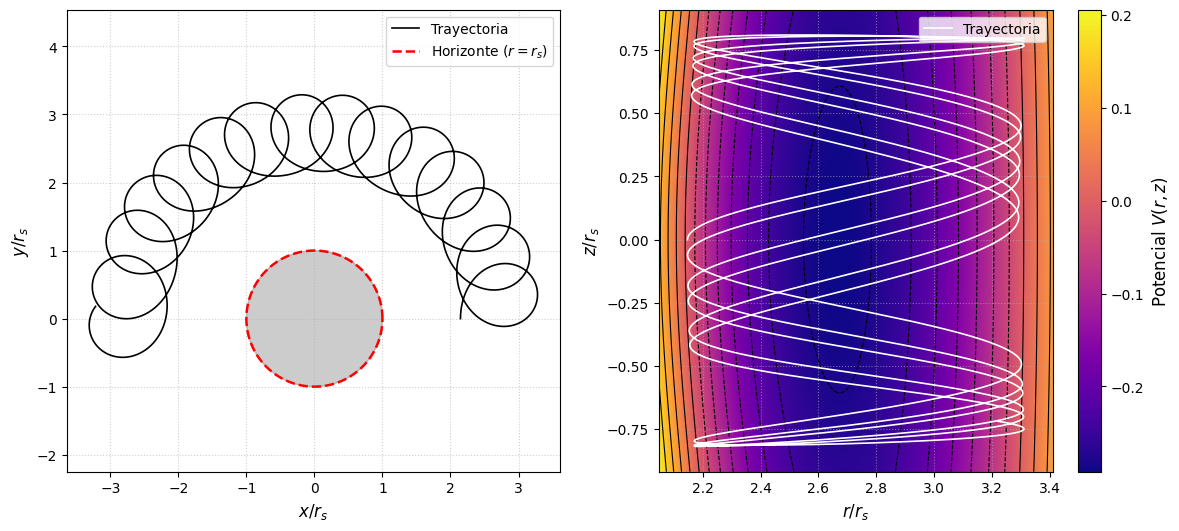

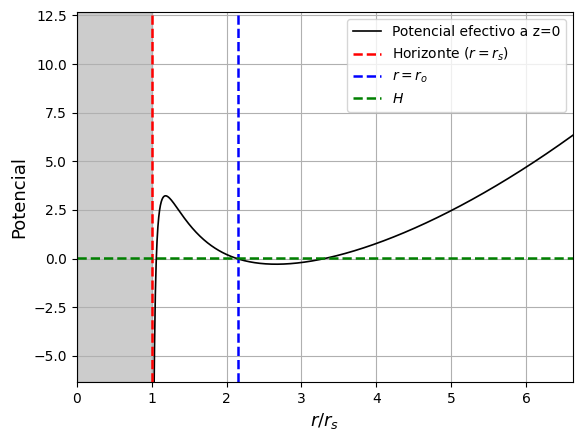

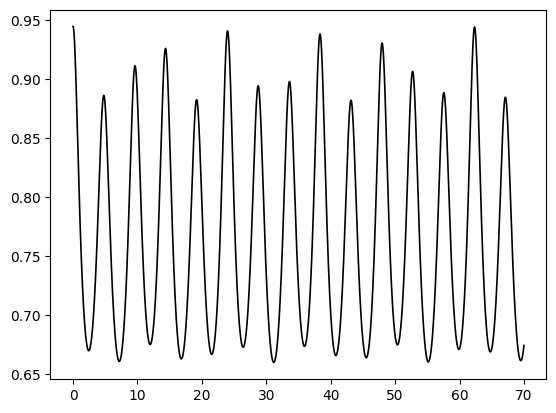

In [46]:
'''#######################################################################################################################################
########## Definición de parametros y CIs

b = 0.655

params = (b,)

P = 5
ro = 2.1467
dphio = P/ro**2 - b
zo = 0
dzo = 0.2
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo] # po, phio, zo, pdo, phido, zdo

Ho = dro**2/2 + dzo**2 /2 + ro**2 * dphio**2 / 2 - 1/(2*sp.sqrt(ro**2 + zo**2) - 2)

tf = 70
t_eval = np.linspace(0, tf, 100000)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

time = sol.t
r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

#######################################################################################################################################
########## TRAYECTORIA EN XY

# Trayectoria de la partícula en xy
ax1.plot(x_n, y_n, label= f"Trayectoria", color="black", lw=1.2)

# Dibujar el horizonte de Schwarzschild (círculo r' = 1)
theta = np.linspace(0, 2 * np.pi, 300)
x_horizon = np.cos(theta)
y_horizon = np.sin(theta)

ax1.plot(x_horizon, y_horizon, "r--", lw=1.8, label = r"Horizonte ($r=r_s$)")
ax1.fill(x_horizon, y_horizon, color="black", alpha=0.2)  # Sombreado interior

# Formato y aspecto 1:1
ax1.set_aspect("equal", adjustable="datalim")
ax1.set_xlabel(r"$x/r_s$", fontsize=12)
ax1.set_ylabel(r"$y/r_s$", fontsize=12)
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend()

#######################################################################################################################################
######### TRAYECTORIA EN ZR Y POTENCIAL EFECTIVO

R = np.linspace(min(r_n)-0.1, max(r_n)+0.1, 1000)
Z = np.linspace(min(z_n)-0.1, max(z_n)+0.1, 1000)

R_grid, Z_grid = np.meshgrid(R, Z)

def calcularV(R,Z):
  return (P - b * R**2)**2 / (2 * R**2) - 1 / (2 * np.sqrt(R**2 + Z**2) - 2)

V = calcularV(R_grid, Z_grid)

# Dibujar el mapa de color (Fondo)
# 'cmap' define la paleta (viridis, plasma, inferno, coolwarm, RdBu_r, etc.)
# 'shading="gouraud"' suaviza la transición entre los píxeles
mapa_color = ax2.pcolormesh(R, Z, V, cmap='plasma', shading='gouraud')

# Dibujar las curvas de nivel (Contornos)
# 'levels' define la cantidad de líneas o los valores exactos
curvas = ax2.contour(R, Z, V, levels=12, colors='black', linewidths=0.8, zorder=2)

# Agregar barra de colores (Colorbar) para saber qué significa cada color
barra_color = plt.colorbar(mapa_color)
barra_color.set_label(r'Potencial $V(r, z)$', fontsize=12)

# Trayectoria de la partícula en rz
ax2.plot(r_n, z_n, label="Trayectoria", color="white", lw=1.2)

# Formato y aspecto 1:1
ax2.set_aspect("auto")
ax2.set_xlabel(r"$r/r_s$", fontsize=12)
ax2.set_ylabel(r"$z/r_s$", fontsize=12)
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend(loc="upper right")
plt.show()

#######################################################################################################################################
######### Potencial efectivo en Z = 0

R  = np.linspace(1.01, 2 * max(r_n), 1000)


def calcularVr(R):
  return P**2/(2*R**2) + b**2 * R**2 /2 - 1/(R-1) /2 - P * b

V = calcularVr(R)

plt.plot(R,V, label= f"Potencial efectivo a z=0", color="black", lw=1.2)
plt.axvline(1, color = "r", linestyle = '--', lw=1.8, label = r"Horizonte ($r=r_s$)")
plt.axvline(ro, color = "blue", linestyle = '--', lw=1.8, label = r"$r=r_o$")
plt.axhline(Ho, color = "green", linestyle = '--', lw=1.8, label = r"$H$")

plt.ylim(-max(V), 2 * max(V))
plt.xlim(0, 2*max(r_n))

x = [0, 1, 1, 0]
y = [-max(V), -max(V), 2*max(V), 2*max(V)]
plt.fill(x,y, color="black", alpha=0.2)  # Sombreado interior

plt.ylabel('Potencial', fontsize = 13)
plt.xlabel(r'$r/r_s$', fontsize = 13)
plt.legend()
plt.grid()
plt.show()

#######################################################################################################################################
######### modulo de la velocidad

def calcularvelocidad(r, rd, phid, zd):
  return np.sqrt(rd**2 + r**2 * phid**2 + zd**2)

velocidad = calcularvelocidad(r_n, rd_n, phid_n, zd_n)

plt.plot(time, velocidad, label= f"Módulo de la velocidad", color="black", lw=1.2)
#plt.axhline(1, color = "r", linestyle = '--', lw=1.8, label = r"v = c")'''

In [108]:
#######################################################################################################################################
################# AGUJERO NEGRO CON DIPOLO MAGNETICO

b = sp.symbols(r"b", positive=True)
r, phi, z = sp.symbols(r"r \phi z")
t = sp.symbols("t")

r, phi, z = sp.Function("r")(t), sp.Function(r"\phi")(t), sp.Function(r"z")(t)
rd = r.diff(t)
rdd = rd.diff(t)
phid = phi.diff(t)
phidd = phid.diff(t)
zd = z.diff(t)
zdd = zd.diff(t)

L = ( rd**2 +  r**2 * phid**2  +  zd**2 ) / 2 + b * r**2 * phid / (r**2 + z**2)**(3/2)  + 1 / (2*sp.sqrt(r**2 + z**2) - 2)

eq1 = sp.Eq((L.diff(rd).diff(t) - L.diff(r)), 0)
eq2 = sp.Eq((L.diff(phid).diff(t) - L.diff(phi)), 0)
eq3 = sp.Eq((L.diff(zd).diff(t) - L.diff(z)), 0)

display(eq1)
display(eq2)
display(eq3)

sol = sp.solve([eq1, eq2, eq3], [rdd, phidd, zdd])

args = (r, phi, z, rd, phid, zd, b)
F1 = sp.lambdify(args, [sol[rdd]], modules="numpy", cse=True)
F2 = sp.lambdify(args, [sol[phidd]], modules="numpy", cse=True)
F3 = sp.lambdify(args, [sol[zdd]], modules="numpy", cse=True)

def rhs(t, y, *p):
    r, phi, z, v1, v2, v3 = y
    rd = v1
    phid = v2
    zd = v3
    v1d = F1(r, phi, z, v1, v2, v3, *p)[0]
    v2d = F2(r, phi, z, v1, v2, v3, *p)[0]
    v3d = F3(r, phi, z, v1, v2, v3, *p)[0]
    return [rd, phid, zd, v1d, v2d, v3d]

H = L.diff(rd) * rd + L.diff(phid) * phid + L.diff(zd) * zd - L
display(H)


               -2.5                        -1.5                                ↪
      ⎛ 2    2⎞      3            ⎛ 2    2⎞                    2               ↪
3.0⋅b⋅⎝r  + z ⎠    ⋅r ⋅\pḣi - 2⋅b⋅⎝r  + z ⎠    ⋅r⋅\pḣi - r⋅\pḣi  + r̈ + ─────── ↪
                                                                               ↪
                                                                       ⎛     _ ↪
                                                                       ⎜    ╱  ↪
                                                                       ⎝2⋅╲╱   ↪

↪                                
↪         2⋅r                    
↪ ─────────────────────────── = 0
↪              2                 
↪ ________    ⎞     _________    
↪  2    2     ⎟    ╱  2    2     
↪ r  + z   - 2⎠ ⋅╲╱  r  + z      

                                -2.5                   -1.5                    ↪
                       ⎛ 2    2⎞      2       ⎛ 2    2⎞            2           ↪
b⋅(-3.0⋅r⋅ṙ - 3.0⋅z⋅ż)⋅⎝r  + z ⎠    ⋅r  + 2⋅b⋅⎝r  + z ⎠    ⋅r⋅ṙ + r ⋅\pḧi + 2⋅ ↪

↪             
↪             
↪ r⋅\pḣi⋅ṙ = 0

               -2.5                                                       
      ⎛ 2    2⎞      2                             2⋅z                    
3.0⋅b⋅⎝r  + z ⎠    ⋅r ⋅z⋅\pḣi + z̈ + ────────────────────────────────── = 0
                                                        2                 
                                    ⎛     _________    ⎞     _________    
                                    ⎜    ╱  2    2     ⎟    ╱  2    2     
                                    ⎝2⋅╲╱  r  + z   - 2⎠ ⋅╲╱  r  + z      

             -1.5           ⎛           -1.5             ⎞         2     2     ↪
    ⎛ 2    2⎞      2        ⎜  ⎛ 2    2⎞      2    2     ⎟        r ⋅\pḣi    ṙ ↪
- b⋅⎝r  + z ⎠    ⋅r ⋅\pḣi + ⎝b⋅⎝r  + z ⎠    ⋅r  + r ⋅\pḣi⎠⋅\pḣi - ──────── + ─ ↪
                                                                     2       2 ↪
                                                                               ↪
                                                                               ↪

↪ 2    2                     
↪     ż            1         
↪ ─ + ── - ──────────────────
↪     2         _________    
↪              ╱  2    2     
↪          2⋅╲╱  r  + z   - 2

dphio = -0.6479492187499999


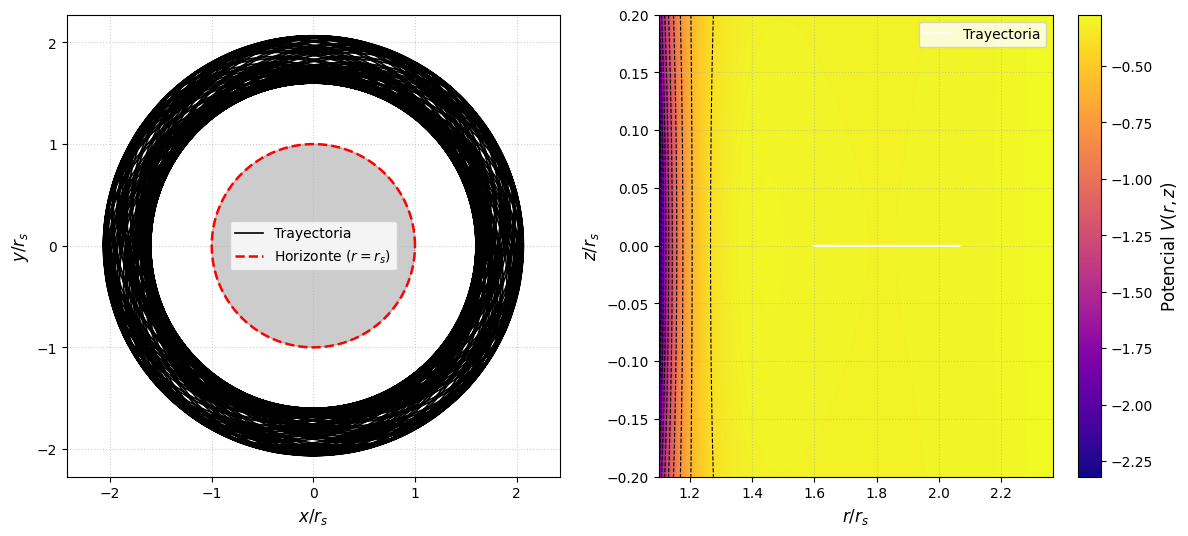

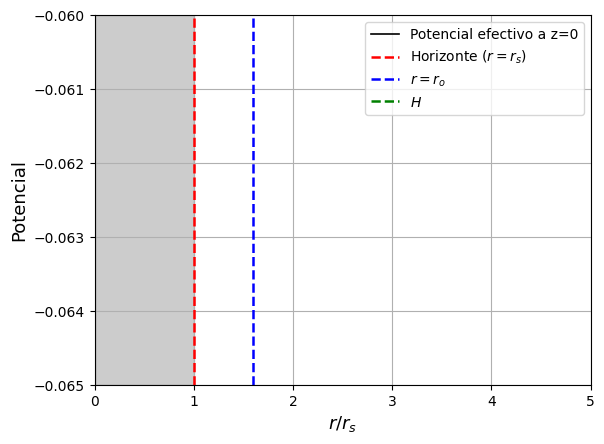

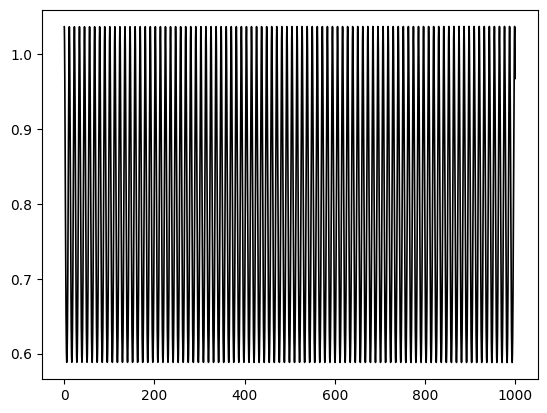

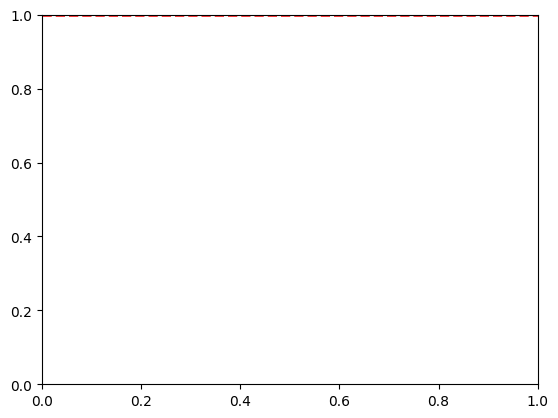

In [48]:
'''#######################################################################################################################################
########## Definición de parametros y CIs

b = 3.1436
P = 0.306

params = (b,)

ro = 1.6

zo = 0
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
print(f'dphio = {dphio}')
dzo = 0
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo] # po, phio, zo, pdo, phido, zdo

Ho = dro**2/2 + dzo**2 /2 + ro**2 * dphio**2 / 2 - 1/(2*sp.sqrt(ro**2 + zo**2) - 2)

tf = 1000
t_eval = np.linspace(0, tf, 100000)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

time = sol.t
r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

#######################################################################################################################################
########## TRAYECTORIA EN XY

# Trayectoria de la partícula en xy
ax1.plot(x_n, y_n, label= f"Trayectoria", color="black", lw=1.2)

# Dibujar el horizonte de Schwarzschild (círculo r' = 1)
theta = np.linspace(0, 2 * np.pi, 300)
x_horizon = np.cos(theta)
y_horizon = np.sin(theta)

ax1.plot(x_horizon, y_horizon, "r--", lw=1.8, label = r"Horizonte ($r=r_s$)")
ax1.fill(x_horizon, y_horizon, color="black", alpha=0.2)  # Sombreado interior

# Formato y aspecto 1:1
ax1.set_aspect("equal", adjustable="datalim")
ax1.set_xlabel(r"$x/r_s$", fontsize=12)
ax1.set_ylabel(r"$y/r_s$", fontsize=12)
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend()

#######################################################################################################################################
######### TRAYECTORIA EN ZR Y POTENCIAL EFECTIVO

R = np.linspace(min(r_n)-0.5,  max(r_n)+0.3, 1000)
Z = np.linspace( -max(z_n) - 0.2,  max(z_n)+0.2, 1000)

R_grid, Z_grid = np.meshgrid(R, Z)

def calcularV(R, Z):
    return (1 / (2 * R**2)) * (P - b * R**2 / (R**2 + Z**2)**(3/2))**2 - 1 / (2 * np.sqrt(R**2 + Z**2) - 2)

V = calcularV(R_grid, Z_grid)

# Dibujar el mapa de color (Fondo)
# 'cmap' define la paleta (viridis, plasma, inferno, coolwarm, RdBu_r, etc.)
# 'shading="gouraud"' suaviza la transición entre los píxeles
mapa_color = ax2.pcolormesh(R, Z, V, cmap='plasma', shading='gouraud')

# Dibujar las curvas de nivel
# 'levels' define la cantidad de líneas o los valores exactos
curvas = ax2.contour(R, Z, V, levels=12, colors='black', linewidths=0.8, zorder=2)

# Agregar barra de colores (Colorbar) para saber qué significa cada color
barra_color = plt.colorbar(mapa_color)
barra_color.set_label(r'Potencial $V(r, z)$', fontsize=12)

# Trayectoria de la partícula en rz
ax2.plot(r_n, z_n, label="Trayectoria", color="white", lw=1.2)

# Formato y aspecto 1:1
ax2.set_aspect("auto")
ax2.set_xlabel(r"$r/r_s$", fontsize=12)
ax2.set_ylabel(r"$z/r_s$", fontsize=12)
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend(loc="upper right")
plt.show()

#######################################################################################################################################
######### Potencial efectivo en Z = 0

R  = np.linspace(1.01, max(r_n) + 2, 100000)

def calcularVr(R):
    return P**2 / (2 * R**2) + b**2 / (2 * R**4) - (b * P) / R**3 - 1 / (2 * (R - 1))

Ho = calcularVr(ro)
V = calcularVr(R)

plt.plot(R,V, label= f"Potencial efectivo a z=0", color="black", lw=1.2)
plt.axvline(1, color = "r", linestyle = '--', lw=1.8, label = r"Horizonte ($r=r_s$)")
plt.axvline(ro, color = "blue", linestyle = '--', lw=1.8, label = r"$r=r_o$")
plt.axhline(Ho, color = "green", linestyle = '--', lw=1.8, label = r"$H$")

x2 = 5
y1 = -0.065
y2 = -0.06

plt.ylim(y1, y2)
plt.xlim(0, x2)

x = [0, 1, 1, 0]
y = [y1, y1, y2, y2]
plt.fill(x,y, color="black", alpha=0.2)  # Sombreado interior

plt.ylabel('Potencial', fontsize = 13)
plt.xlabel(r'$r/r_s$', fontsize = 13)
plt.legend()
plt.grid()
plt.show()

#######################################################################################################################################
######### modulo de la velocidad

def calcularvelocidad(r, rd, phid, zd):
  return np.sqrt(rd**2 + r**2 * phid**2 + zd**2)

velocidad = calcularvelocidad(r_n, rd_n, phid_n, zd_n)

plt.plot(time, velocidad, label= f"Módulo de la velocidad", color="black", lw=1.2)
plt.show()
plt.axhline(1, color = "r", linestyle = '--', lw=1.8, label = r"v = c")'''

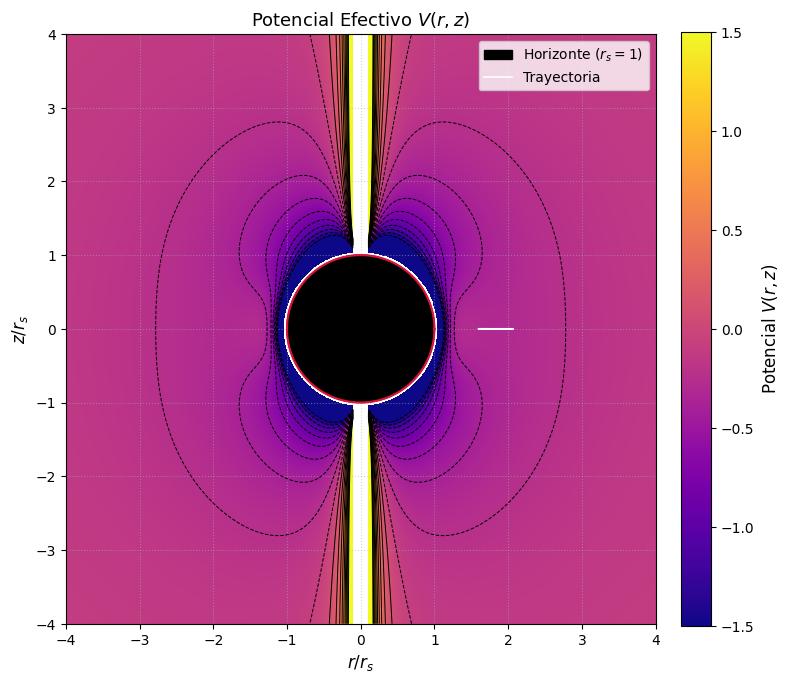

In [49]:
'''#######################################################################################################################################
################# POTENCIAL EFECTIVO COMPLETO EN RZ

n = 4

r_lin = np.linspace(-n, n, 1200)
z_lin = np.linspace(-n, n, 1200)
R_grid, Z_grid = np.meshgrid(r_lin, z_lin)

def calcularV(R, Z):
    dist = np.sqrt(R**2 + Z**2)
    term_ang = (1 / (2 * R**2)) * (P - b * (R**2) / (dist**3))**2
    term_grav = 1 / (2 * (dist - 1))
    return term_ang - term_grav

V = calcularV(R_grid, Z_grid)

# Enmascarar la singularidad del agujero negro y el eje R=0
dist = np.sqrt(R_grid**2 + Z_grid**2)
# Se excluye el interior y una vecindad microscópica del horizonte
mascara = (dist <= 1.04) | (np.abs(R_grid) < 0.1)
V[mascara] = np.nan

# runcar valores numéricos divergentes para preservar la escala de color
# Evita que valores como -100 o +500 saturen toda la paleta
V_recortado = np.clip(V, -2.0, 2.0)

fig, ax = plt.subplots(figsize=(8, 8))

# 5. Mapa de color y contornos continuos
mapa = ax.pcolormesh(
    R_grid, Z_grid, V_recortado,
    cmap='plasma', shading='auto',
    vmin=-1.5, vmax=1.5
)

niveles = np.linspace(-1.5, 1.5, 20)
curvas = ax.contour(
    R_grid, Z_grid, V,
    levels=niveles, colors='black', linewidths=0.7, zorder=2
)

# 6. Dibujar el horizonte de sucesos (círculo r_s = 1) en el centro
theta = np.linspace(0, 2 * np.pi, 400)
ax.fill(np.cos(theta), np.sin(theta), color='black', zorder=5, label='Horizonte ($r_s=1$)')
ax.plot(np.cos(theta), np.sin(theta), color='crimson', lw=1.5, zorder=6)

# Barra de colores y formato
barra_color = fig.colorbar(mapa, ax=ax, fraction=0.046, pad=0.04)
barra_color.set_label(r'Potencial $V(r, z)$', fontsize=12)

ax.plot(r_n, z_n, label="Trayectoria", color="white", lw=1.2)

ax.set_aspect('equal', adjustable='box')
ax.set_xlim(-n, n)
ax.set_ylim(-n, n)
ax.set_xlabel(r"$r/r_s$", fontsize=12)
ax.set_ylabel(r"$z/r_s$", fontsize=12)
ax.set_title(r"Potencial Efectivo $V(r, z)$", fontsize=13)
ax.grid(True, ls=":", alpha=0.5)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()'''

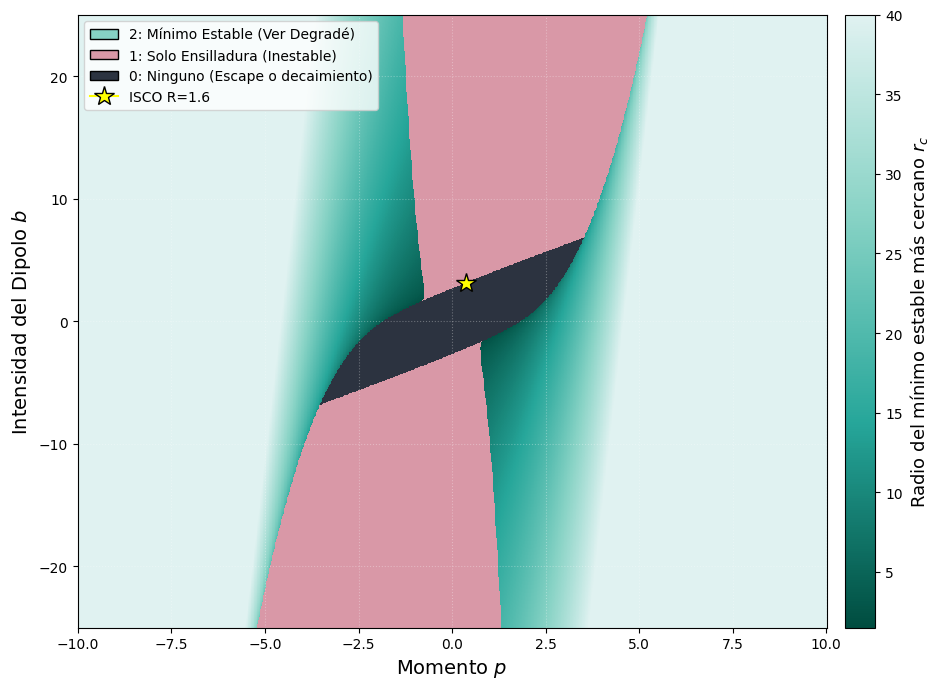

In [95]:
#######################################################################################################################################
################# ANALISIS DE ESTABILIDAD EN FUNCION DE LOS PARAMETROS P Y b

# Definición Analítica del Hessiano

def H_rr(r, P, b):
    return (3*P**2)/r**4 - (12*b*P)/r**5 + (10*b**2)/r**6 - 1.0/(r-1)**3

def H_zz(r, P, b):
    return (3*b*P)/r**5 - (3*b**2)/r**6 + 0.5/(r * (r-1)**2)

# Configuración de la Grilla
res = 1000
P_vals = np.linspace(-10, 10, res)
b_vals = np.linspace(-25, 25, res)
P_grid, b_grid = np.meshgrid(P_vals, b_vals)

Z_map = np.zeros((res, res), dtype=int)
R_map = np.full((res, res), np.nan) # Matriz nueva para guardar el radio exacto

# Bucle Principal de Mapeo
for i in range(res):
    for j in range(res):
        P_val = P_grid[i, j]
        b_val = b_grid[i, j]

        # Coeficientes del polinomio de grado 5
        c5 = 1.0
        c4 = -2 * P_val**2
        c3 = 4 * P_val**2 + 6 * b_val * P_val
        c2 = -2 * P_val**2 - 12 * b_val * P_val - 4 * b_val**2
        c1 = 6 * b_val * P_val + 8 * b_val**2
        c0 = -4 * b_val**2

        todas_las_raices = np.roots([c5, c4, c3, c2, c1, c0])

        # Filtrar solo raíces reales físicas
        raices_validas = []
        for raiz in todas_las_raices:
            if np.isreal(raiz) and np.real(raiz) > 1.01:
                rc = np.real(raiz)
                es_nueva = True
                for r_existente in raices_validas:
                    if abs(rc - r_existente) < 1e-4:
                        es_nueva = False
                        break
                if es_nueva:
                    raices_validas.append(rc)

        # Clasificación y Extracción de r_c
        if len(raices_validas) == 0:
            Z_map[i, j] = 0
        else:
            tiene_minimo_estable = False
            tiene_ensilladura = False
            radios_estables = []

            for rc in raices_validas:
                hrr = H_rr(rc, P_val, b_val)
                hzz = H_zz(rc, P_val, b_val)

                if hrr > -1e-7 and hzz > -1e-7:
                    tiene_minimo_estable = True
                    radios_estables.append(rc)
                elif hrr < -1e-7 or hzz < -1e-7:
                    tiene_ensilladura = True

            if tiene_minimo_estable:
                Z_map[i, j] = 2
                # Guardamos el mínimo estable más cercano al horizonte (el menor r_c)
                R_map[i, j] = min(radios_estables)
            elif tiene_ensilladura:
                Z_map[i, j] = 1
            else:
                Z_map[i, j] = 0

# Generación del Gráfico
fig, ax = plt.subplots(figsize=(10, 7))

# Paleta para las zonas base (Escape y Ensilladura)
color_escape = '#2c3340'  # Gris azulado mate
color_saddle = '#d998a7'  # Rosa pastel mate
cmap_base = ListedColormap([color_escape, color_saddle])

# Enmascarar la zona estable en Z_map para que sea transparente y deje ver el degradé
Z_base = np.where(Z_map == 2, np.nan, Z_map)
ax.pcolormesh(P_grid, b_grid, Z_base, cmap=cmap_base, shading='nearest')

# Degradé
gradient = LinearSegmentedColormap.from_list("Grad", ["#004d40", "#26a69a", "#86d2c4", "#e0f2f1"])

# Graficar el mapa de distancias R_map
# vmax recorta el degradé en r=15 para que las órbitas muy lejanas no laven el contraste visual cerca de 1
mesh_R = ax.pcolormesh(P_grid, b_grid, R_map, cmap= gradient, shading='nearest', vmin=1.5, vmax=40)

# Barra de color para interpretar la distancia r
cbar = fig.colorbar(mesh_R, ax=ax, pad=0.02)
cbar.set_label(r'Radio del mínimo estable más cercano $r_c$', fontsize=13)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#86d2c4', edgecolor='k', label='2: Mínimo Estable (Ver Degradé)'),
    Patch(facecolor=color_saddle, edgecolor='k', label='1: Solo Ensilladura (Inestable)'),
    Patch(facecolor=color_escape, edgecolor='k', label='0: Ninguno (Escape o decaimiento)')
]

# Marcar el punto exacto de la ISCO
ax.plot(0.3676, 3.1436, marker='*', markersize=15, color='yellow', markeredgecolor='black', label="ISCO R=1.6")
ax.legend(handles=legend_elements + [ax.get_legend_handles_labels()[0][-1]], loc='upper left')

ax.set_xlabel(r'Momento $p$', fontsize=14)
ax.set_ylabel(r'Intensidad del Dipolo $b$', fontsize=14)
ax.grid(True, ls=':', alpha=0.3, color='white')

plt.tight_layout()
plt.show()

In [103]:
#######################################################################################################################################
################# CALCULO DE LAS CURVAS (p^Crit, b^crit) para varios r_ISCO

# Acá tuve que separar en dos listas porque en p = 0 hay una discontinuidad (se me rompían las cosas)

P_ISCO1 = []
b_ISCO1 = []
P_ISCO2 = []
b_ISCO2 = []
limite = 1.66
RISCO_1 = np.linspace(1.203, limite, 20)
RISCO_2 = np.linspace(limite+0.01, 23.8, 20)

def calcular_r_isco(P_val, b_val, R_isco):
  b, P = sp.symbols('b P', real=True)
  r = sp.symbols('r', positive=True)

  V = P**2 / (2*r**2) + b**2 / (2*r**4) - (b * P) / r**3 - 0.5 / (r - 1)

  eq1 = sp.Eq(V.diff(r), 0)
  eq2 = sp.Eq(V.diff(r).diff(r), 0)
  eq1_eval = eq1.subs(r, R_isco)
  eq2_eval = eq2.subs(r, R_isco)

  # Resolver el sistema cuadrático numéricamente
  # dict=True devuelve una lista de diccionarios, facilitando la extracción

  soluciones = sp.solve([eq1_eval, eq2_eval], [b, P], dict=True)

  for i, sol in enumerate(soluciones):
    # Extraer valores numéricos con coma flotante (evalf)
    b_val = sol[b].evalf()
    P_val = sol[P].evalf()
  return P_val, b_val

for i in range(len(RISCO_1)):
  P_val, b_val = calcular_r_isco(P_val, b_val, RISCO_1[i])
  P_ISCO1.append(P_val)
  b_ISCO1.append(b_val)

for i in range(len(RISCO_2)):
  P_val, b_val = calcular_r_isco(P_val, b_val, RISCO_2[i])
  P_ISCO2.append(P_val)
  b_ISCO2.append(b_val)


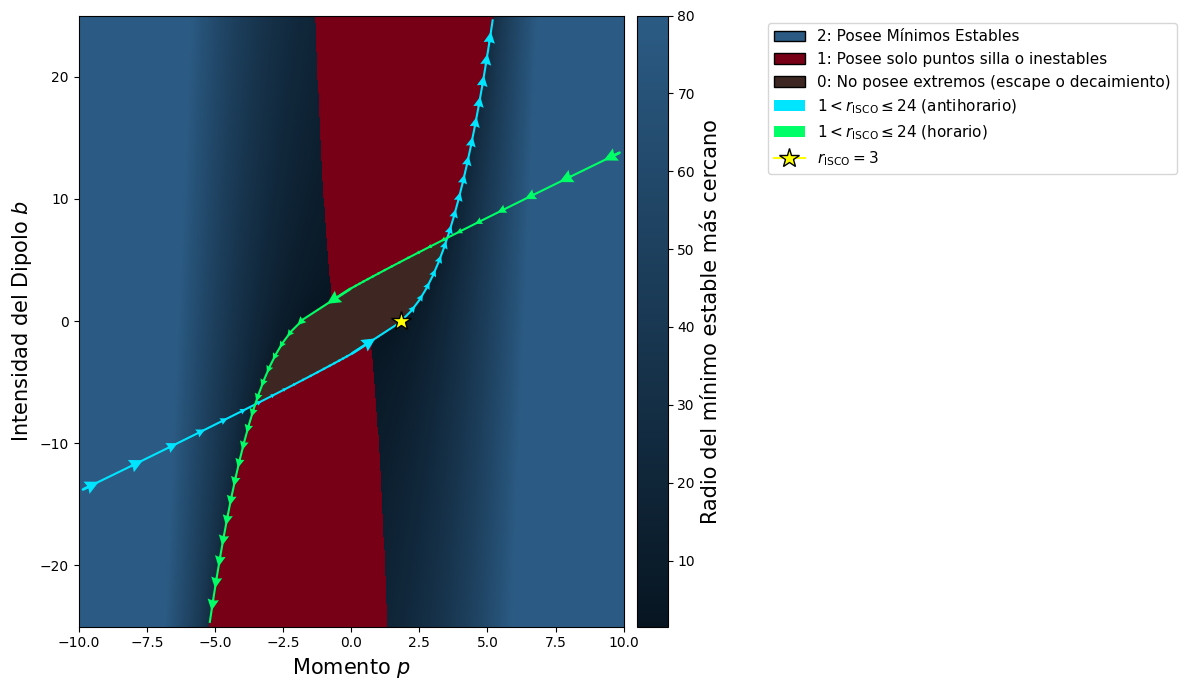

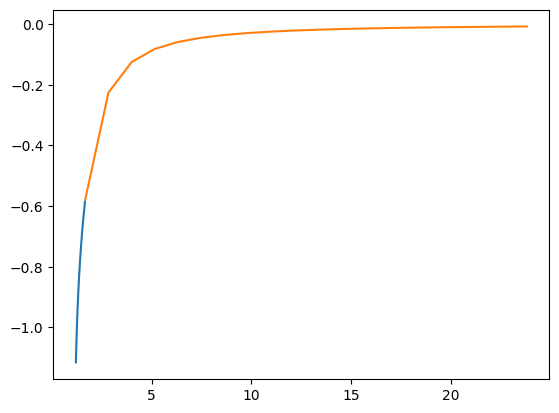

In [152]:
# OBS: por como se definen las listas, las curvas van a volverse locas cada vez que compilás y cambiar de sentido, eso es porque
# aproveché las simetría para poner -p, -b y que me de la otra curva.

# Valores estrella

P3, b3 = calcular_r_isco(P_val, b_val, 3)
P15, b15 = calcular_r_isco(P_val, b_val, 15)
P1, b1 = calcular_r_isco(P_val, b_val, 1.3)

# Generación del Gráfico
fig, ax = plt.subplots(figsize=(10, 7))

# Paleta pastel mate para las zonas base (Escape y Ensilladura)
color_escape = '#3E2723'
color_saddle = '#780016'
cmap_base = ListedColormap([color_escape, color_saddle])

color_r_chico = '#2B5B84'  # Azul medio (para el r más cercano a 1)
color_r_grande = '#071521' # Azul casi negro (para r grande)
mi_degrade = LinearSegmentedColormap.from_list('zafiro', [color_r_grande, color_r_chico])

# Enmascarar la zona estable en Z_map para que sea transparente y deje ver el degradé
Z_base = np.where(Z_map == 2, np.nan, Z_map)
ax.pcolormesh(P_grid, b_grid, Z_base, cmap=cmap_base, shading='nearest')

# Graficar el mapa de distancias R_map
# vmax recorta el degradé en r=15 para que las órbitas muy lejanas no laven el contraste visual cerca de 1
mesh_R = ax.pcolormesh(P_grid, b_grid, R_map, cmap= mi_degrade, shading='nearest', vmin=1.5, vmax=80)

# Barra de color para interpretar la distancia r
cbar = fig.colorbar(mesh_R, ax=ax, pad=0.02)
cbar.set_label(r'Radio del mínimo estable más cercano', fontsize=15 )

# Curva antihorario

P_ISCO1 = -np.array(P_ISCO1).astype(float)
b_ISCO1 = -np.array(b_ISCO1).astype(float)
P_ISCO2 = np.array(P_ISCO2).astype(float)
b_ISCO2 = np.array(b_ISCO2).astype(float)

u1 = np.diff(P_ISCO1)
v1 = np.diff(b_ISCO1)

u2 = np.diff(P_ISCO2)
v2 = np.diff(b_ISCO2)

ax.plot(P_ISCO1, b_ISCO1, color='#00E5FF')
plt.quiver(P_ISCO1[:-1], b_ISCO1[:-1], u1, v1, angles='xy', scale_units='xy', scale=3,
           color='#00E5FF', width=0.005, headwidth=5, headlength=5)

ax.plot(P_ISCO2, b_ISCO2, color='#00E5FF')
plt.quiver(P_ISCO2[:-1], b_ISCO2[:-1], u2, v2, angles='xy', scale_units='xy', scale=2,
           color='#00E5FF', width=0.005, headwidth=5, headlength=5)

# Curva horario

P_ISCO1 = -np.array(P_ISCO1).astype(float)
b_ISCO1 = -np.array(b_ISCO1).astype(float)
P_ISCO2 = -np.array(P_ISCO2).astype(float)
b_ISCO2 = -np.array(b_ISCO2).astype(float)

u1 = np.diff(P_ISCO1)
v1 = np.diff(b_ISCO1)

u2 = np.diff(P_ISCO2)
v2 = np.diff(b_ISCO2)

ax.plot(P_ISCO1, b_ISCO1, color='#00FF66')
plt.quiver(P_ISCO1[:-1], b_ISCO1[:-1], u1, v1, angles='xy', scale_units='xy', scale=3,
           color='#00FF66', width=0.005, headwidth=5, headlength=5)

ax.plot(P_ISCO2, b_ISCO2, color='#00FF66')
plt.quiver(P_ISCO2[:-1], b_ISCO2[:-1], u2, v2, angles='xy', scale_units='xy', scale=2,
           color='#00FF66', width=0.005, headwidth=5, headlength=5)

# VALORES ESTRELLA RISCO

ax.plot(P3, b3, marker='*', markersize=15, color='yellow', markeredgecolor='black', label = r'$r_\text{ISCO} = 3$')
#ax.plot(-P1, -b1, marker='*', markersize=15, color='red', markeredgecolor='black', label = r'$r_\text{ISCO} = 1.3$')
#ax.plot(P15, b15, marker='*', markersize=15, color='blue', markeredgecolor='black', label = r'$r_\text{ISCO} = 15$')
#ax.plot(1.2, -2.5, marker='*', markersize=15, color='#FF1053', markeredgecolor='black')

# La ultima estrella me ayuda a elegir valores interesantes de p y b para graficar luego
########################

ax.set_xlabel(r'Momento $p$', fontsize=15)
ax.set_ylabel(r'Intensidad del Dipolo $b$', fontsize=15)
#ax.grid(True, ls=':', alpha=0, color='white')

legend_elements = [
    Patch(facecolor='#2B5B84', edgecolor='k', label='2: Posee Mínimos Estables'),
    Patch(facecolor='#780016', edgecolor='k', label='1: Posee solo puntos silla o inestables'),
    Patch(facecolor='#3E2723', edgecolor='k', label='0: No posee extremos (escape o decaimiento)'),
    Patch(facecolor='#00E5FF', label= r"$1 < r_\text{ISCO} \leq 24$ (antihorario)" ),
    Patch(facecolor='#00FF66', label= r"$1 < r_\text{ISCO} \leq 24$ (horario)")]

box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.75, box.height])
#+[ax.get_legend_handles_labels()[0][1]]+[ax.get_legend_handles_labels()[0][0]]

# 3. Ubicamos la leyenda AFUERA
# bbox_to_anchor=(1.05, 1) significa: x=1.05 (afuera a la derecha), y=1 (arriba)
ax.legend(handles=legend_elements
          + [ax.get_legend_handles_labels()[0][-1]],
          loc='upper left',
          bbox_to_anchor=(1.25, 1),
          fontsize=11)

plt.tight_layout()
plt.show()

# PLOTEO DE LA VELOCIDAD ANGULAR para una de las curvas

plt.plot(RISCO_1, P_ISCO1/RISCO_1**2 - b_ISCO1/(RISCO_1**3))
plt.plot(RISCO_2, P_ISCO2/RISCO_2**2 - b_ISCO2/(RISCO_2**3))
plt.show()

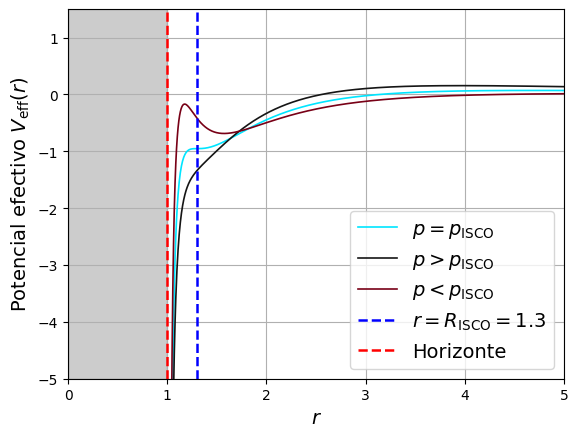

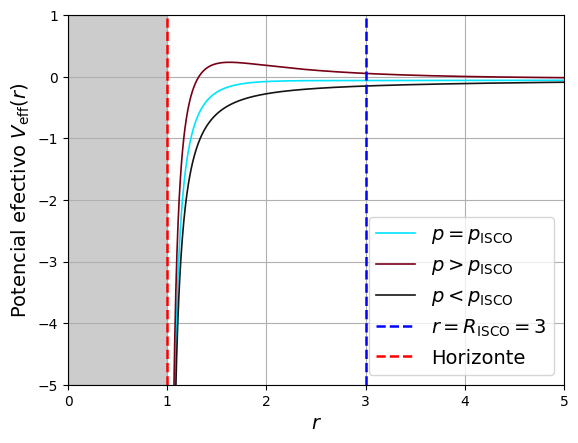

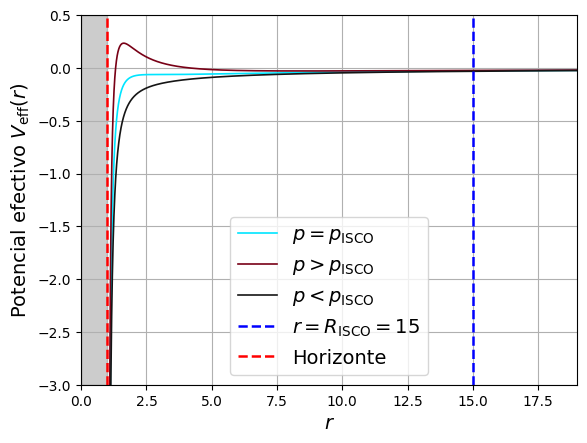

P1 = 4.75446381278237, b1 = 8.19949612283198
P3 = 1.83711730708738, b3 = 0
P15 = 4.15379593570700, b15 = 11.9275430713641


In [109]:
#######################################################################################################################################
################# POTENCIAL EN R PERTURBANDO P PARA 3 ISCO

R  = np.linspace(1.01, 20, 5000)

def calcularVr(R, P, b):
    return P**2 / (2 * R**2) + b**2 / (2 * R**4) - (b * P) / R**3 - 1 / (2 * (R- 1))

# PLOTEO DEL POTENCIAL para RISCO = 1.3

V1 = calcularVr(R, P1, b1)
V2 = calcularVr(R, P1 + 0.5, b1)
V3 = calcularVr(R, P1 - 0.5, b1)

plt.plot(R, V1, label= r"$p = p_\text{ISCO}$", color="#00E5FF", lw=1.2)
plt.plot(R, V2, label= r"$p > p_\text{ISCO}$", color="#151515", lw=1.2)
plt.plot(R, V3, label= r"$p < p_\text{ISCO}$", color="#780016", lw=1.2)

plt.axvline(1.3, color = "blue", linestyle = '--', lw=1.8, label = r"$r = R_\text{ISCO} = 1.3$")

plt.axvline(1, color = "r", linestyle = '--', lw=1.8, label = r"Horizonte")

x2 = 5
y1 = -5
y2 = 1.5

plt.ylim(y1, y2)
plt.xlim(0, x2)

x = [0, 1, 1, 0]
y = [y1, y1, y2, y2]
plt.fill(x,y, color="black", alpha=0.2)  # Sombreado interior

plt.ylabel(r'Potencial efectivo $V_\text{eff}(r)$', fontsize = 14)
plt.xlabel(r'$r$', fontsize = 14)
plt.legend(fontsize = 14)
plt.grid()
plt.show()

# PLOTEO DEL POTENCIAL EN R para RISCO = 3

V1 = calcularVr(R, P3, b3)
V2 = calcularVr(R, P3 + 0.5, b3)
V3 = calcularVr(R, P3 - 0.5, b3)

plt.plot(R, V1, label= r"$p = p_\text{ISCO}$", color="#00E5FF", lw=1.2)
plt.plot(R, V2, label= r"$p >p_\text{ISCO}$", color="#780016", lw=1.2)
plt.plot(R, V3, label= r"$p < p_\text{ISCO}$", color="#151515", lw=1.2)

plt.axvline(3, color = "blue", linestyle = '--', lw=1.8, label = r"$r = R_\text{ISCO} = 3$")

plt.axvline(1, color = "r", linestyle = '--', lw=1.8, label = r"Horizonte")

x2 = 5
y1 = -5
y2 = 1

plt.ylim(y1, y2)
plt.xlim(0, x2)

x = [0, 1, 1, 0]
y = [y1, y1, y2, y2]
plt.fill(x,y, color="black", alpha=0.2)  # Sombreado interior

plt.ylabel(r'Potencial efectivo $V_\text{eff}(r)$', fontsize = 14)
plt.xlabel(r'$r$', fontsize = 14)
plt.legend(fontsize = 14)
plt.grid()
plt.show()

# PLOTEO DEL POTENCIAL EN R para RISCO = 15

V1 = calcularVr(R, P3, b3)
V2 = calcularVr(R, P3 + 0.5, b3)
V3 = calcularVr(R, P3 - 0.5, b3)

plt.plot(R, V1, label= r"$p = p_\text{ISCO}$", color="#00E5FF", lw=1.2)
plt.plot(R, V2, label= r"$p > p_\text{ISCO}$", color="#780016", lw=1.2)
plt.plot(R, V3, label= r"$p < p_\text{ISCO}$", color="#151515", lw=1.2)

plt.axvline(15, color = "blue", linestyle = '--', lw=1.8, label = r"$r = R_\text{ISCO} = 15$")

plt.axvline(1, color = "r", linestyle = '--', lw=1.8, label = r"Horizonte")

x2 = 19
y1 = -3
y2 = 0.5

plt.ylim(y1, y2)
plt.xlim(0, x2)

x = [0, 1, 1, 0]
y = [y1, y1, y2, y2]
plt.fill(x,y, color="black", alpha=0.2)  # Sombreado interior

plt.ylabel(r'Potencial efectivo $V_\text{eff}(r)$', fontsize = 14)
plt.xlabel(r'$r$', fontsize = 14)
plt.legend(fontsize = 14)
plt.grid()
plt.show()

print(f"P1 = {P1}, b1 = {b1}")
print(f"P3 = {P3}, b3 = {b3}")
print(f"P15 = {P15}, b15 = {b15}")

dphio = 0.03490960709383433


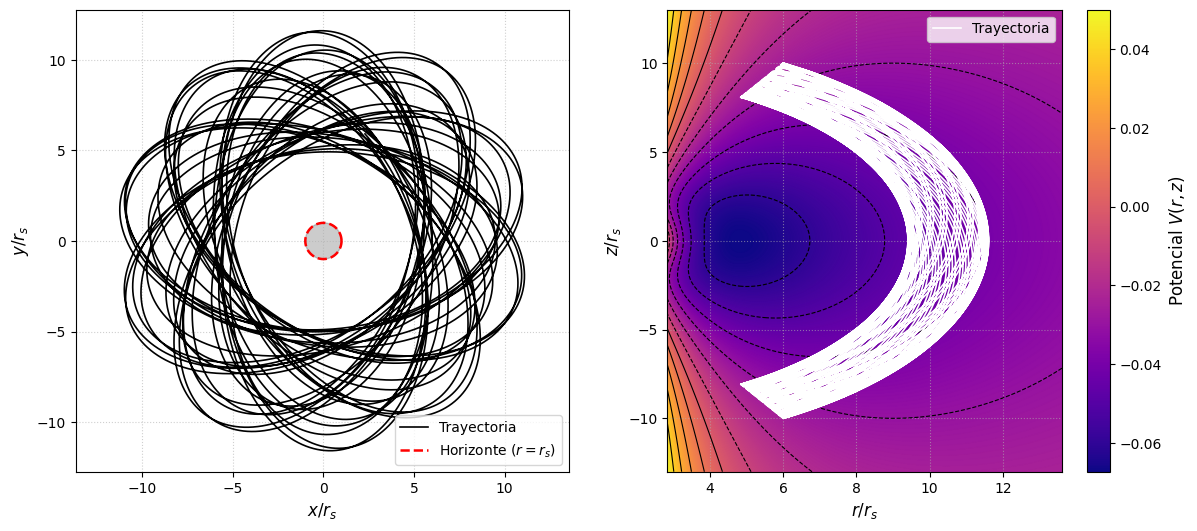

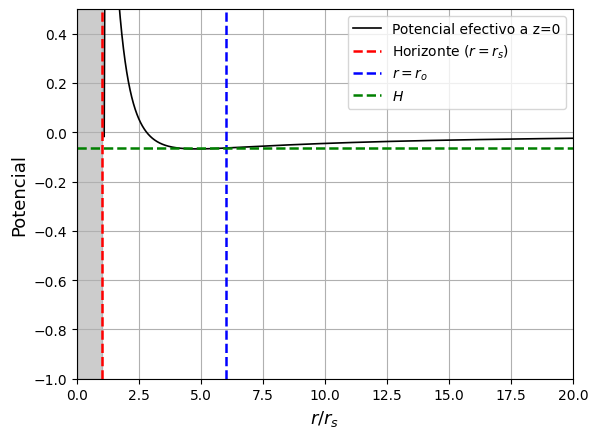

In [54]:
'''b = -3
P = 1.4'''

b = -2.5
P = 1.2
params = (b,)

ro = 6

zo = 10
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
print(f'dphio = {dphio}')
dzo = 0
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo] # po, phio, zo, pdo, phido, zdo

Ho = dro**2/2 + dzo**2 /2 + ro**2 * dphio**2 / 2 - 1/(2*sp.sqrt(ro**2 + zo**2) - 2)

tf = 10000
t_eval = np.linspace(0, tf, 100000)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method= 'Radau', rtol=1e-6, atol=1e-5)

time = sol.t
r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

#######################################################################################################################################
########## TRAYECTORIA EN XY

# Trayectoria de la partícula en xy
ax1.plot(x_n, y_n, label= f"Trayectoria", color="black", lw=1.2)

# Dibujar el horizonte de Schwarzschild (círculo r' = 1)
theta = np.linspace(0, 2 * np.pi, 300)
x_horizon = np.cos(theta)
y_horizon = np.sin(theta)

ax1.plot(x_horizon, y_horizon, "r--", lw=1.8, label = r"Horizonte ($r=r_s$)")
ax1.fill(x_horizon, y_horizon, color="black", alpha=0.2)  # Sombreado interior

# Formato y aspecto 1:1
ax1.set_aspect("equal", adjustable="datalim")
ax1.set_xlabel(r"$x/r_s$", fontsize=12)
ax1.set_ylabel(r"$y/r_s$", fontsize=12)
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend()

#######################################################################################################################################
######### TRAYECTORIA EN ZR Y POTENCIAL EFECTIVO

R = np.linspace(min(r_n)-2,  max(r_n)+2, 1000)
Z = np.linspace( min(z_n) - 3,  max(z_n)+3, 1000)

R_grid, Z_grid = np.meshgrid(R, Z)

def calcularV(R, Z):
    return (1 / (2 * R**2)) * (P - b * R**2 / (R**2 + Z**2)**(3/2))**2 - 1 / (2 * np.sqrt(R**2 + Z**2) - 2)

V = calcularV(R_grid, Z_grid)

# Dibujar el mapa de color (Fondo)
# 'cmap' define la paleta (viridis, plasma, inferno, coolwarm, RdBu_r, etc.)
# 'shading="gouraud"' suaviza la transición entre los píxeles
mapa_color = ax2.pcolormesh(R, Z, V, cmap='plasma', shading='gouraud')

# Dibujar las curvas de nivel (Contornos)
# 'levels' define la cantidad de líneas o los valores exactos
curvas = ax2.contour(R, Z, V, levels=12, colors='black', linewidths=0.8, zorder=2)

# Agregar barra de colores (Colorbar) para saber qué significa cada color
barra_color = plt.colorbar(mapa_color)
barra_color.set_label(r'Potencial $V(r, z)$', fontsize=12)

# Trayectoria de la partícula en rz
ax2.plot(r_n, z_n, label="Trayectoria", color="white", lw=1.2)

# Formato y aspecto 1:1
ax2.set_aspect("auto")
ax2.set_xlabel(r"$r/r_s$", fontsize=12)
ax2.set_ylabel(r"$z/r_s$", fontsize=12)
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend(loc="upper right")
plt.show()

#######################################################################################################################################
######### Potencial efectivo en Z = 0

R  = np.linspace(1.1, 100, 100000)

def calcularVr(R):
    return P**2 / (2 * R**2) + b**2 / (2 * R**4) - (b * P) / R**3 - 1 / (2 * (R - 1))

Ho = calcularVr(ro)
V = calcularVr(R)

plt.plot(R,V, label= f"Potencial efectivo a z=0", color="black", lw=1.2)
plt.axvline(1, color = "r", linestyle = '--', lw=1.8, label = r"Horizonte ($r=r_s$)")
plt.axvline(ro, color = "blue", linestyle = '--', lw=1.8, label = r"$r=r_o$")
plt.axhline(Ho, color = "green", linestyle = '--', lw=1.8, label = r"$H$")

x2 = 20
y1 = -1
y2 = 0.5

plt.ylim(y1, y2)
plt.xlim(0, x2)

x = [0, 1, 1, 0]
y = [y1, y1, y2, y2]
plt.fill(x,y, color="black", alpha=0.2)  # Sombreado interior

plt.ylabel('Potencial', fontsize = 13)
plt.xlabel(r'$r/r_s$', fontsize = 13)
plt.legend()
plt.grid()
plt.show()

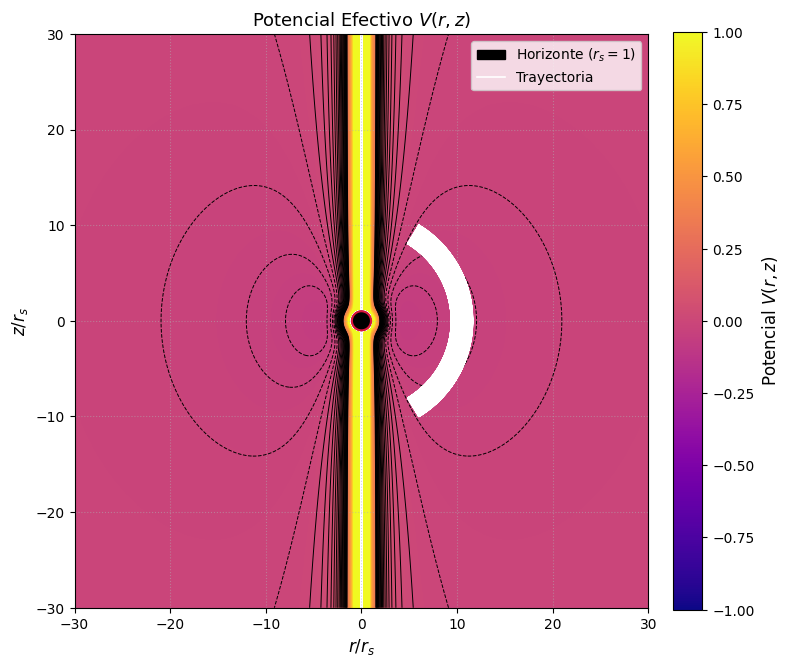

In [55]:
import numpy as np
import matplotlib.pyplot as plt

n = 30

r_lin = np.linspace(-n, n, 1200)
z_lin = np.linspace(-n, n, 1200)
R_grid, Z_grid = np.meshgrid(r_lin, z_lin)

def calcularV(R, Z):
    dist = np.sqrt(R**2 + Z**2)
    term_ang = (1 / (2 * R**2)) * (P - b * (R**2) / (dist**3))**2
    term_grav = 1 / (2 * (dist - 1))
    return term_ang - term_grav

V = calcularV(R_grid, Z_grid)

# Enmascarar la singularidad del agujero negro y el eje R=0
dist = np.sqrt(R_grid**2 + Z_grid**2)
# Se excluye el interior y una vecindad microscópica del horizonte
mascara = (dist <= 1.17) | (np.abs(R_grid) < 0.2)
V[mascara] = np.nan

# runcar valores numéricos divergentes para preservar la escala de color
# Evita que valores como -100 o +500 saturen toda la paleta
V_recortado = np.clip(V, -1, 1)

fig, ax = plt.subplots(figsize=(8, 8))

# 5. Mapa de color y contornos continuos
mapa = ax.pcolormesh(
    R_grid, Z_grid, V_recortado,
    cmap='plasma', shading='auto',
    vmin=-1, vmax=1
)

niveles = np.linspace(-0.3, 0.3, 40)
curvas = ax.contour(
    R_grid, Z_grid, V,
    levels=niveles, colors='black', linewidths=0.7, zorder=2
)

# 6. Dibujar el horizonte de sucesos (círculo r_s = 1) en el centro
theta = np.linspace(0, 2 * np.pi, 400)
ax.fill(np.cos(theta), np.sin(theta), color='black', zorder=5, label='Horizonte ($r_s=1$)')
ax.plot(np.cos(theta), np.sin(theta), color='crimson', lw=1.5, zorder=6)

# Barra de colores y formato
barra_color = fig.colorbar(mapa, ax=ax, fraction=0.046, pad=0.04)
barra_color.set_label(r'Potencial $V(r, z)$', fontsize=12)

ax.plot(r_n, z_n, label="Trayectoria", color="white", lw=1.2)

ax.set_aspect('equal', adjustable='box')
ax.set_xlim(-n, n)
ax.set_ylim(-n, n)
ax.set_xlabel(r"$r/r_s$", fontsize=12)
ax.set_ylabel(r"$z/r_s$", fontsize=12)
ax.set_title(r"Potencial Efectivo $V(r, z)$", fontsize=13)
ax.grid(True, ls=":", alpha=0.5)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

dphio = 0.03490960709383433
Guardando animación a disco... esto puede tomar unos segundos.
¡Listo! Guardado como 'orbita_sgrA.mp4'


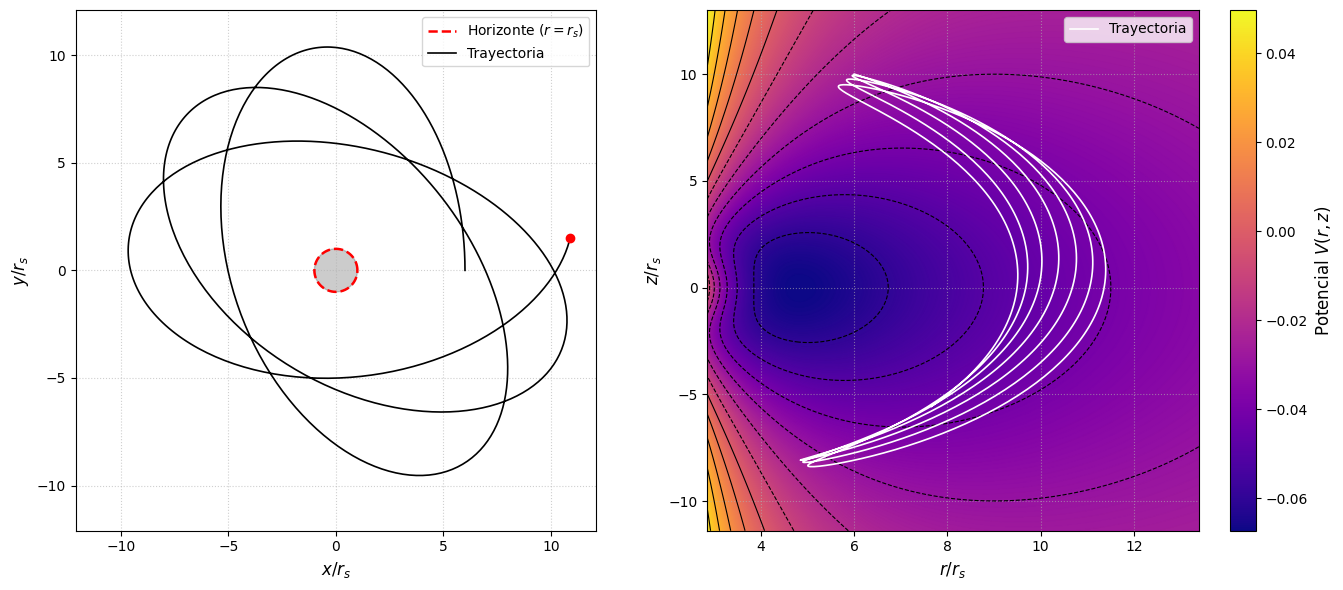

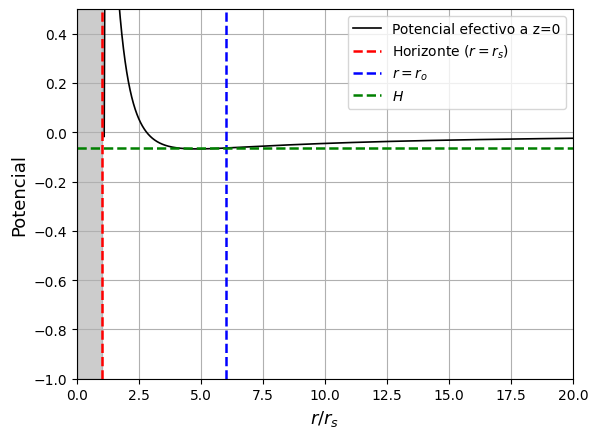

In [56]:
'''import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
from scipy.integrate import solve_ivp

b = -2.5
P = 1.2
params = (b,)

ro = 6
zo = 10
dphio = P / ro**2 - b / (ro**2 + zo**2)**(3/2)
print(f'dphio = {dphio}')
dzo = 0
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo] # po, phio, zo, pdo, phido, zdo

tf = 1000
t_eval = np.linspace(0, tf, 100)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method='Radau', rtol=1e-6, atol=1e-5)

time = sol.t
r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

#######################################################################################################################################
########## TRAYECTORIA EN XY (ANIMADA)

# Dibujar el horizonte de Schwarzschild (círculo r' = 1)
theta = np.linspace(0, 2 * np.pi, 300)
x_horizon = np.cos(theta)
y_horizon = np.sin(theta)

ax1.plot(x_horizon, y_horizon, "r--", lw=1.8, label=r"Horizonte ($r=r_s$)")
ax1.fill(x_horizon, y_horizon, color="black", alpha=0.2)

# Elementos actualizables de la animación
linea_anim, = ax1.plot([], [], color="black", lw=1.2, label="Trayectoria")
punto_particula, = ax1.plot([], [], marker='o', markersize=6, color="red")

# Fijar escala estática para que la cámara no oscile
margen = 1.1
max_val = max(np.max(np.abs(x_n)), np.max(np.abs(y_n))) * margen
ax1.set_xlim(-max_val, max_val)
ax1.set_ylim(-max_val, max_val)

ax1.set_aspect("equal")
ax1.set_xlabel(r"$x/r_s$", fontsize=12)
ax1.set_ylabel(r"$y/r_s$", fontsize=12)
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend()

#######################################################################################################################################
######### TRAYECTORIA EN ZR Y POTENCIAL EFECTIVO

R = np.linspace(min(r_n) - 2, max(r_n) + 2, 1000)
Z = np.linspace(min(z_n) - 3, max(z_n) + 3, 1000)

R_grid, Z_grid = np.meshgrid(R, Z)

def calcularV(R, Z):
    return (1 / (2 * R**2)) * (P - b * R**2 / (R**2 + Z**2)**(3/2))**2 - 1 / (2 * (np.sqrt(R**2 + Z**2) - 1))

V = calcularV(R_grid, Z_grid)

mapa_color = ax2.pcolormesh(R, Z, V, cmap='plasma', shading='gouraud')
curvas = ax2.contour(R, Z, V, levels=12, colors='black', linewidths=0.8, zorder=2)

barra_color = plt.colorbar(mapa_color, ax=ax2)
barra_color.set_label(r'Potencial $V(r, z)$', fontsize=12)

# Trayectoria completa de referencia en rz
ax2.plot(r_n, z_n, label="Trayectoria", color="white", lw=1.2)

ax2.set_aspect("auto")
ax2.set_xlabel(r"$r/r_s$", fontsize=12)
ax2.set_ylabel(r"$z/r_s$", fontsize=12)
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend(loc="upper right")

plt.tight_layout()

#######################################################################################################################################
######### CONFIGURACIÓN Y GUARDADO DE LA ANIMACIÓN

step = 200  # Toma 500 cuadros (renderizado rápido y fluido)
indices = np.arange(0, len(x_n), step)

def actualizar(frame):
    linea_anim.set_data(x_n[:frame], y_n[:frame])
    punto_particula.set_data([x_n[frame]], [y_n[frame]])
    return linea_anim, punto_particula

anim = FuncAnimation(fig, actualizar, frames=indices, interval=25, blit=True)

# Guardar a disco local para poder descargarla
print("Guardando animación a disco... esto puede tomar unos segundos.")
try:
    # 1. Intenta guardar como MP4 (requiere ffmpeg instalado en el entorno)
    anim.save('orbita_sgrA.mp4', writer=FFMpegWriter(fps=30, bitrate=1800))
    print("¡Listo! Guardado como 'orbita_sgrA.mp4'")
except Exception:
    # 2. Si no tenés ffmpeg, lo guarda como GIF automáticamente sin depender de nada
    anim.save('orbita_sgrA.gif', writer=PillowWriter(fps=30))
    print("¡Listo! Guardado como 'orbita_sgrA.gif'")

plt.show()

#######################################################################################################################################
######### Potencial efectivo en Z = 0

R = np.linspace(1.1, 100, 100000)

def calcularVr(R):
    return P**2 / (2 * R**2) + b**2 / (2 * R**4) - (b * P) / R**3 - 1 / (2 * (R - 1))

Ho = calcularVr(ro)
V = calcularVr(R)

plt.figure()
plt.plot(R, V, label=f"Potencial efectivo a z=0", color="black", lw=1.2)
plt.axvline(1, color="r", linestyle='--', lw=1.8, label=r"Horizonte ($r=r_s$)")
plt.axvline(ro, color="blue", linestyle='--', lw=1.8, label=r"$r=r_o$")
plt.axhline(Ho, color="green", linestyle='--', lw=1.8, label=r"$H$")

x2 = 20
y1 = -1
y2 = 0.5

plt.ylim(y1, y2)
plt.xlim(0, x2)

x = [0, 1, 1, 0]
y = [y1, y1, y2, y2]
plt.fill(x, y, color="black", alpha=0.2)

plt.ylabel('Potencial', fontsize=13)
plt.xlabel(r'$r/r_s$', fontsize=13)
plt.legend()
plt.grid()
plt.show()'''

dphio = 0.19301303412082


/tmp/ipykernel_2769/1212397744.py:47: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  ax1.plot(x_ISCO, y_ISCO, "r--", lw=1.8, label = r"ISCO ($r=3$)", color = 'gray')
/tmp/ipykernel_2769/1212397744.py:150: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  ax3.plot(x_ISCO, y_ISCO, "r--", lw=1.8, label = r"ISCO ($r=3$)", color = 'gray')


dphio = 0.20412414523193112
dphio = 0.21523525634304225


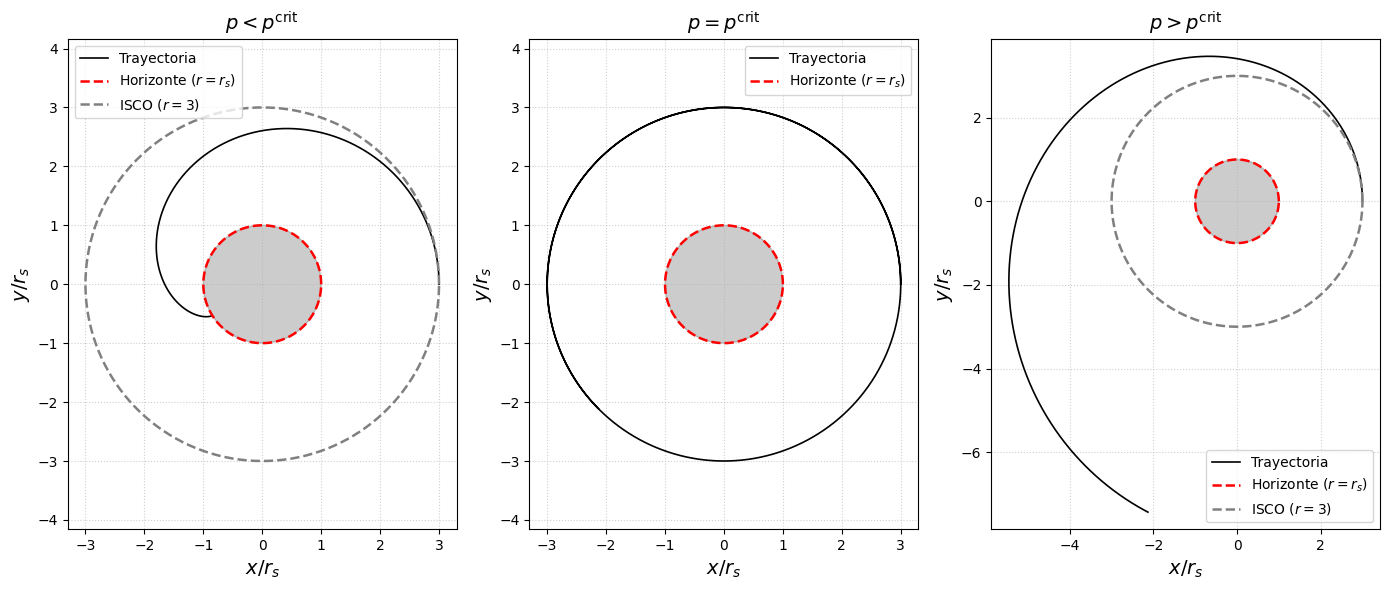

In [143]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
b = 0

#######################################################################################################################################
########## P < PCRIT

P = 1.83711730708738 - 0.1

params = (b,)

ro = 3

zo = 0
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
print(f'dphio = {dphio}')
dzo = 0
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo] # po, phio, zo, pdo, phido, zdo

Ho = dro**2/2 + dzo**2 /2 + ro**2 * dphio**2 / 2 - 1/(2*sp.sqrt(ro**2 + zo**2) - 2)

tf = 500
t_eval = np.linspace(0, tf, 100000)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

time = sol.t
r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

# Trayectoria de la partícula en xy
ax1.plot(x_n, y_n, label= f"Trayectoria", color="black", lw=1.2)

# Dibujar el horizonte de Schwarzschild (círculo r' = 1)
theta = np.linspace(0, 2 * np.pi, 300)
x_horizon = np.cos(theta)
y_horizon = np.sin(theta)

ax1.plot(x_horizon, y_horizon, "r--", lw=1.8, label = r"Horizonte ($r=r_s$)")
ax1.fill(x_horizon, y_horizon, color="black", alpha=0.2)  # Sombreado interior

x_ISCO = 3 *np.cos(theta)
y_ISCO = 3 *np.sin(theta)
ax1.plot(x_ISCO, y_ISCO, "r--", lw=1.8, label = r"ISCO ($r=3$)", color = 'gray')

# Formato y aspecto 1:1
ax1.set_title(r"$p<p^\text{crit}$", fontsize = 14)
ax1.set_aspect("equal", adjustable="datalim")
ax1.set_xlabel(r"$x/r_s$", fontsize=14)
ax1.set_ylabel(r"$y/r_s$", fontsize=14)
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend()

#######################################################################################################################################
########## P = PCRIT

P = 1.83711730708738

params = (b,)

ro = 3

zo = 0
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
print(f'dphio = {dphio}')
dzo = 0
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo] # po, phio, zo, pdo, phido, zdo

Ho = dro**2/2 + dzo**2 /2 + ro**2 * dphio**2 / 2 - 1/(2*sp.sqrt(ro**2 + zo**2) - 2)

tf = 50
t_eval = np.linspace(0, tf, 100000)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

time = sol.t
r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

# Trayectoria de la partícula en xy
ax2.plot(x_n, y_n, label= f"Trayectoria", color="black", lw=1.2)

# Dibujar el horizonte de Schwarzschild (círculo r' = 1)
theta = np.linspace(0, 2 * np.pi, 300)
x_horizon = np.cos(theta)
y_horizon = np.sin(theta)

ax2.plot(x_horizon, y_horizon, "r--", lw=1.8, label = r"Horizonte ($r=r_s$)")
ax2.fill(x_horizon, y_horizon, color="black", alpha=0.2)  # Sombreado interior

# Formato y aspecto 1:1
ax2.set_title(r"$p=p^\text{crit}$", fontsize = 14)
ax2.set_aspect("equal", adjustable="datalim")
ax2.set_xlabel(r"$x/r_s$", fontsize=14)
ax2.set_ylabel(r"$y/r_s$", fontsize=14)
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend()

#######################################################################################################################################
########## P > PCRIT

P = 1.83711730708738 + 0.1

params = (b,)

ro = 3

zo = 0
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
print(f'dphio = {dphio}')
dzo = 0
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo] # po, phio, zo, pdo, phido, zdo

Ho = dro**2/2 + dzo**2 /2 + ro**2 * dphio**2 / 2 - 1/(2*sp.sqrt(ro**2 + zo**2) - 2)

'''tf = 1650'''
tf = 50
t_eval = np.linspace(0, tf, 100000)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

time = sol.t
r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

# Trayectoria de la partícula en xy
ax3.plot(x_n, y_n, label= f"Trayectoria", color="black", lw=1.2)

# Dibujar el horizonte de Schwarzschild (círculo r' = 1)
theta = np.linspace(0, 2 * np.pi, 300)
x_horizon = np.cos(theta)
y_horizon = np.sin(theta)

ax3.plot(x_horizon, y_horizon, "r--", lw=1.8, label = r"Horizonte ($r=r_s$)")
ax3.fill(x_horizon, y_horizon, color="black", alpha=0.2)  # Sombreado interior

x_ISCO = 3 *np.cos(theta)
y_ISCO = 3 *np.sin(theta)
ax3.plot(x_ISCO, y_ISCO, "r--", lw=1.8, label = r"ISCO ($r=3$)", color = 'gray')

# Formato y aspecto 1:1
ax3.set_title(r"$p>p^\text{crit}$", fontsize = 14)
ax3.set_aspect("equal", adjustable="datalim")
ax3.set_xlabel(r"$x/r_s$", fontsize=14)
ax3.set_ylabel(r"$y/r_s$", fontsize=14)
ax3.grid(True, ls=":", alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.show()




dphio = 0.19301303412082


/tmp/ipykernel_2769/4249376952.py:72: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  ax1.plot(3*np.cos(theta), 3*np.sin(theta), "r--", lw=1.8, label=r"ISCO ($r=3$)", color='gray')
/tmp/ipykernel_2769/4249376952.py:159: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  ax3.plot(3*np.cos(theta), 3*np.sin(theta), "r--", lw=1.8, label=r"ISCO ($r=3$)", color='gray')


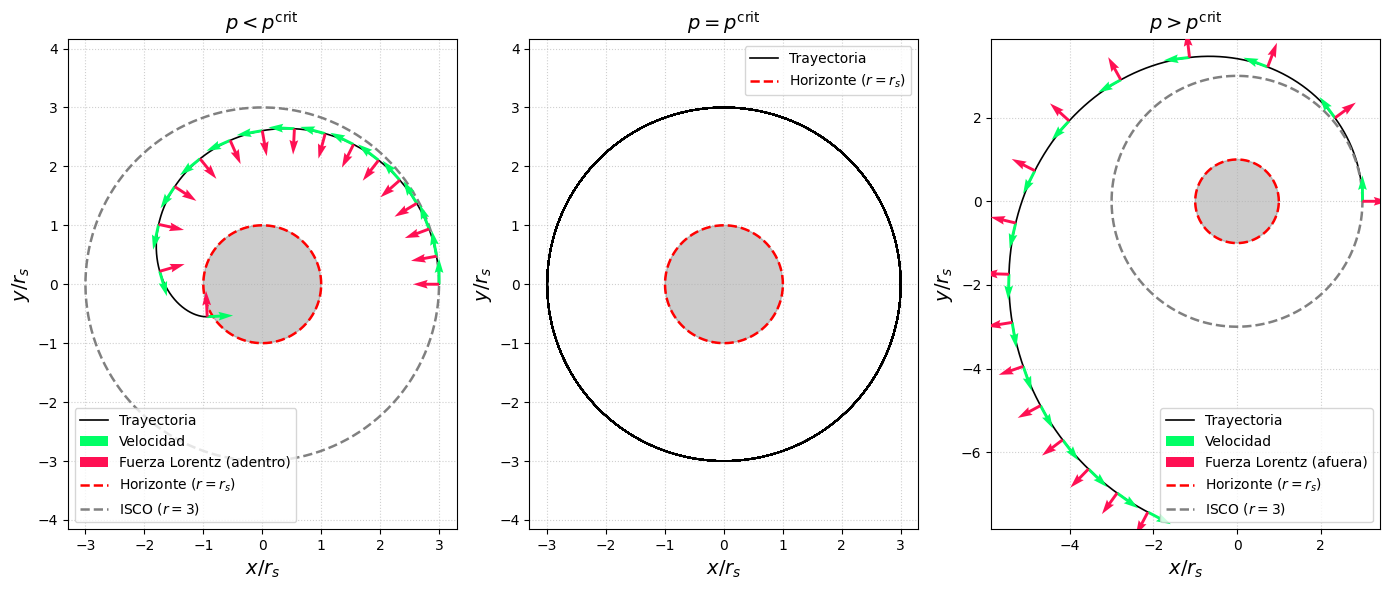

In [139]:
'''import numpy as np
import scipy as sp
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Asumo que la función rhs está definida previamente en tu código original
# def rhs(t, y, b): ...

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
b = 0 # todo esto es ilustrativo, no hace falta que b>0

#######################################################################################################################################
########## P < PCRIT

P = 1.83711730708738 - 0.1
params = (b,)
ro = 3
zo = 0
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
print(f'dphio = {dphio}')
dzo = 0
dro = 0
y0 = [ro, 0, zo, dro, dphio, dzo]

# Ho = dro**2/2 + dzo**2/2 + ro**2*dphio**2 / 2 - 1/(2*sp.sqrt(ro**2 + zo**2)-2)

tf = 500
t_eval = np.linspace(0, tf, 100000)

sol = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

r_n, phi_n, z_n = sol.y[0], sol.y[1], sol.y[2]
rd_n, phid_n, zd_n = sol.y[3], sol.y[4], sol.y[5]

x_n = r_n * np.cos(phi_n)
y_n = r_n * np.sin(phi_n)

# Calcular velocidades cartesianas para los vectores
vx_n = rd_n * np.cos(phi_n) - r_n * phid_n * np.sin(phi_n)
vy_n = rd_n * np.sin(phi_n) + r_n * phid_n * np.cos(phi_n)

# Seleccionar puntos para graficar flechas (ej. 15 puntos a lo largo de la trayectoria)
paso1 = max(1, len(x_n) // 15)
idx1 = np.arange(0, len(x_n), paso1)

x_f1, y_f1 = x_n[idx1], y_n[idx1]
vx_f1, vy_f1 = vx_n[idx1], vy_n[idx1]

# Normalizar la velocidad
norm_v1 = np.sqrt(vx_f1**2 + vy_f1**2)
norm_v1[norm_v1 == 0] = 1 # Evitar división por cero
vx_f1_norm = vx_f1 / norm_v1
vy_f1_norm = vy_f1 / norm_v1

# Fuerza perpendicular ("hacia adentro")
f_x1 = -vy_f1_norm
f_y1 = vx_f1_norm

# Trayectoria de la partícula en xy
ax1.plot(x_n, y_n, label="Trayectoria", color="black", lw=1.2)

# Vectores en AX1
ax1.quiver(x_f1, y_f1, vx_f1_norm, vy_f1_norm, color='#00FF66', scale=15, pivot='tail', zorder=5, label='Velocidad')
ax1.quiver(x_f1, y_f1, f_x1, f_y1, color='#FF1053', scale=15, pivot='tail', zorder=5, label='Fuerza Lorentz (adentro)')

# Dibujar el horizonte y la ISCO
theta = np.linspace(0, 2*np.pi, 300)
x_horizon, y_horizon = np.cos(theta), np.sin(theta)

ax1.plot(x_horizon, y_horizon, "r--", lw=1.8, label=r"Horizonte ($r=r_s$)")
ax1.fill(x_horizon, y_horizon, color="black", alpha=0.2)
ax1.plot(3*np.cos(theta), 3*np.sin(theta), "r--", lw=1.8, label=r"ISCO ($r=3$)", color='gray')

# Formato AX1
ax1.set_title(r"$p<p^\text{crit}$", fontsize=14)
ax1.set_aspect("equal", adjustable="datalim")
ax1.set_xlabel(r"$x/r_s$", fontsize=14)
ax1.set_ylabel(r"$y/r_s$", fontsize=14)
ax1.grid(True, ls=":", alpha=0.6)
ax1.legend()


#######################################################################################################################################
########## P = PCRIT

P = 1.83711730708738
params = (b,)
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
y0 = [ro, 0, zo, dro, dphio, dzo]

tf = 1000
t_eval = np.linspace(0, tf, 100000)

sol2 = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

r_n2, phi_n2 = sol2.y[0], sol2.y[1]
x_n2 = r_n2 * np.cos(phi_n2)
y_n2 = r_n2 * np.sin(phi_n2)

ax2.plot(x_n2, y_n2, label="Trayectoria", color="black", lw=1.2)
ax2.plot(x_horizon, y_horizon, "r--", lw=1.8, label=r"Horizonte ($r=r_s$)")
ax2.fill(x_horizon, y_horizon, color="black", alpha=0.2)

ax2.set_title(r"$p=p^\text{crit}$", fontsize=14)
ax2.set_aspect("equal", adjustable="datalim")
ax2.set_xlabel(r"$x/r_s$", fontsize=14)
ax2.set_ylabel(r"$y/r_s$", fontsize=14)
ax2.grid(True, ls=":", alpha=0.6)
ax2.legend()


#######################################################################################################################################
########## P > PCRIT

P = 1.83711730708738 + 0.1
params = (b,)
dphio = P/ro**2 - b/(ro**2 + zo**2)**(3/2)
y0 = [ro, 0, zo, dro, dphio, dzo]

tf = 50
t_eval = np.linspace(0, tf, 100000)

sol3 = solve_ivp(rhs, t_span=(0, tf), y0=y0, t_eval=t_eval, args=params, method="DOP853", rtol=1e-6, atol=1e-5)

r_n3, phi_n3, z_n3 = sol3.y[0], sol3.y[1], sol3.y[2]
rd_n3, phid_n3, zd_n3 = sol3.y[3], sol3.y[4], sol3.y[5]

x_n3 = r_n3 * np.cos(phi_n3)
y_n3 = r_n3 * np.sin(phi_n3)

vx_n3 = rd_n3 * np.cos(phi_n3) - r_n3 * phid_n3 * np.sin(phi_n3)
vy_n3 = rd_n3 * np.sin(phi_n3) + r_n3 * phid_n3 * np.cos(phi_n3)

# Seleccionar puntos
paso3 = max(1, len(x_n3) // 15)
idx3 = np.arange(0, len(x_n3), paso3)

x_f3, y_f3 = x_n3[idx3], y_n3[idx3]
vx_f3, vy_f3 = vx_n3[idx3], vy_n3[idx3]

norm_v3 = np.sqrt(vx_f3**2 + vy_f3**2)
norm_v3[norm_v3 == 0] = 1
vx_f3_norm = vx_f3 / norm_v3
vy_f3_norm = vy_f3 / norm_v3

# Fuerza perpendicular ("hacia afuera")
f_x3 = vy_f3_norm
f_y3 = -vx_f3_norm

# Trayectoria de la partícula en xy
ax3.plot(x_n3, y_n3, label="Trayectoria", color="black", lw=1.2)

# Vectores en AX3
ax3.quiver(x_f3, y_f3, vx_f3_norm, vy_f3_norm, color='#00FF66', scale=15, pivot='tail', zorder=5, label='Velocidad')
ax3.quiver(x_f3, y_f3, f_x3, f_y3, color='#FF1053', scale=15, pivot='tail', zorder=5, label='Fuerza Lorentz (afuera)')

ax3.plot(x_horizon, y_horizon, "r--", lw=1.8, label=r"Horizonte ($r=r_s$)")
ax3.fill(x_horizon, y_horizon, color="black", alpha=0.2)
ax3.plot(3*np.cos(theta), 3*np.sin(theta), "r--", lw=1.8, label=r"ISCO ($r=3$)", color='gray')

ax3.set_title(r"$p>p^\text{crit}$", fontsize=14)
ax3.set_aspect("equal", adjustable="datalim")
ax3.set_xlabel(r"$x/r_s$", fontsize=14)
ax3.set_ylabel(r"$y/r_s$", fontsize=14)
ax3.grid(True, ls=":", alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.show()'''